# Lista 2 - Wstęp do uczenia maszynowego
Zuzanna Sosnowska

In [1]:
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from typing import Literal

## Zadanie 1

**Generowanie danych syntetycznych**: Wygeneruj syntetyczny zbiór danych z trzema wyraźnie oddzielonymi skupieniami, używając funkcji
`make blobs` z biblioteki `scikit-learn`. Zwizualizuj dane za pomocą wykresu punktowego.

In [2]:
X, y = make_blobs(n_samples=500, centers=3, n_features=3, random_state=42)

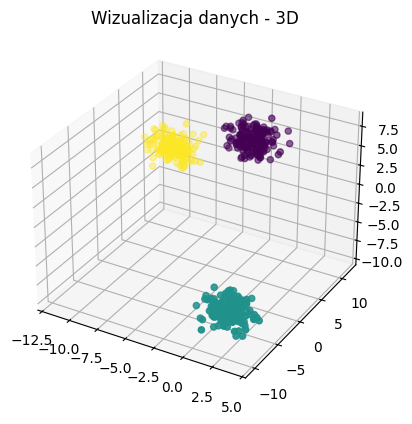

In [3]:
fig = plt.figure()
ax = fig.add_subplot(projection='3d')
ax.scatter(X[:, 0], X[:, 1], X[:, 2], c=y)
plt.title('Wizualizacja danych - 3D')
plt.grid(True)
plt.show()

In [4]:
X, y = make_blobs(n_samples=500, centers=3, n_features=2, random_state=42)

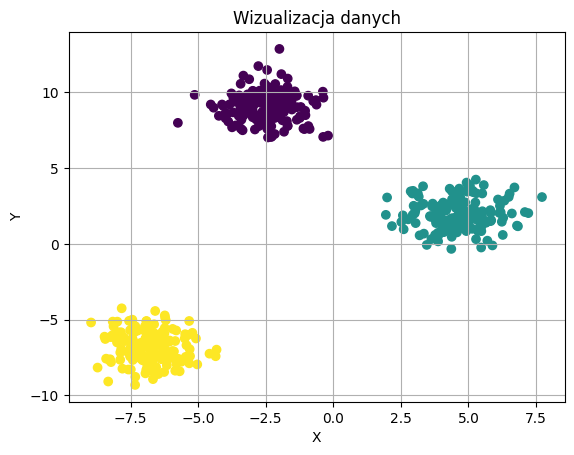

In [5]:
plt.scatter(X[:, 0], X[:, 1], c=y)
plt.title('Wizualizacja danych')
plt.grid(True)
plt.xlabel('X')
plt.ylabel('Y')
plt.show()

## Zadanie 2

**Implementacja algorytmu k-means**: Zaimplementuj algorytm kmeans od podstaw (bez użycia scikit-learn.cluster). Twoja implementacja powinna obejmować:
- Inicjalizację centroidów.
- Pętlę, w której punkty są przypisywane do najbliższego centroidu.
- Aktualizację położenia centroidów jako średniej z przypisanych
punktów.

Przetestuj swój kod na danych z zadania 1.

In [6]:
def initialize_centroids(data: np.ndarray, k: int) -> np.ndarray:
    return data[np.random.choice(data.shape[0], size=k, replace=False)]


def initialize_centroids_plus_plus(
        data: np.ndarray,
        k: int
) -> np.ndarray:
    """
    Funkcja inicjalizuje centroidy metodą kmeans++.
    :param data: Tablica punktów
    :param k: Zadana liczba klastrów
    :return: Funkcja zwraca listę centroidów
    """
    first_centroid = data[np.random.choice(data.shape[0])]
    centroids = [first_centroid]
    for _ in range(k-1):
        points_clusters = assign_clusters(data, centroids)
        distances = [euclidean_distance_squared(centroids[points_clusters[idx]], point) for idx, point in enumerate(data)]
        probabilities = distances / np.sum(distances)
        next_centroid = data[np.random.choice(data.shape[0], p=probabilities)]
        centroids.append(next_centroid)
    return np.array(centroids)


def euclidean_distance_squared(centroid, point):
    return np.sum((centroid - point) ** 2)


def assign_clusters(
        data: np.ndarray,
        centroids: np.ndarray
) -> np.ndarray:
    """
    Funkcja przypisuje klastry do zadanych punktów.
    :param data: Tablica punktów
    :param centroids: Lista centroidów
    :return: Funkcja zwraca tablicę numerów klastrów, przypisanych do odpowiadających punktów.
    """
    clusters = []
    for point in data:
        distances = [euclidean_distance_squared(centroid, point) for centroid in centroids]
        cluster = np.argmin(distances)
        clusters.append(cluster)
    return np.array(clusters)


def update_centroids(
        data: np.ndarray,
        clusters: np.ndarray,
        centroids: np.ndarray
) -> np.ndarray:
    """
    Funkcja aktualizuje centroidy na podstawie średniej z przypisanych do nich punktów.
    :param data: Tablica punktów
    :param clusters: Tablica numerów klastrów
    :param centroids: Tablica centroidów
    :return: Funkcja zwraca zaktualizowaną tablicę centroidów
    """
    for cluster in range(len(centroids)):
        points_in_cluster = data[clusters == cluster]
        if len(points_in_cluster) > 0:
            centroids[cluster] = np.mean(points_in_cluster, axis=0)
    return centroids


def kmeans(
        data: np.ndarray,
        k: int,
        max_iters: int = 20,
        init: Literal['k-means++', 'random'] = 'k-means++'
) -> tuple[np.ndarray, np.ndarray]:

    """
    Funkcja przypisuje punktom klastry, zgodnie z algorytmem kmeans.
    :param data: Tablica punktów
    :param k: Liczba klastrów
    :param max_iters: Maksymalna liczba iteracji algorytmu.
    :param init: Metoda inicjalizacji centroidów. Domyślna metoda to k-means++.
    :return: Funkcja zwraca tuple z tablicą numerów klastrów przypisanych do punktów oraz centroidów tych klastrów.
    """

    if init == 'k-means++':
        centroids = initialize_centroids_plus_plus(data, k)
    else:
        centroids = initialize_centroids(data, k)
    clusters = assign_clusters(data, centroids)
    for _ in range(max_iters):
        centroids = update_centroids(data, clusters, centroids)
        temp_clusters = assign_clusters(data, centroids)
        if list(temp_clusters) == list(clusters):
            break
        clusters = temp_clusters
    centroids = update_centroids(data, clusters, centroids)
    return clusters, centroids

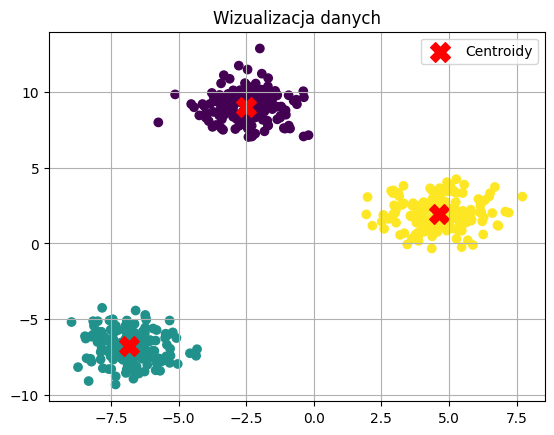

In [7]:
implemented_labels, implemented_centroids = kmeans(X, 3)

plt.scatter(X[:, 0], X[:, 1], c=implemented_labels)
plt.scatter(implemented_centroids[:, 0], implemented_centroids[:, 1], c='r', marker='X', s=200, label='Centroidy')
plt.title('Wizualizacja danych')
plt.grid(True)
plt.legend()
plt.show()

## Zadanie 3
**Zastosowanie algorytmu k-means z biblioteki scikit-learn**:
Użyj klasy `KMeans` z biblioteki `scikit-learn` do pogrupowania danych z zadania 1. Porównaj wyniki z własną implementacją. Zwizualizuj otrzymane klastry, kolorując punkty według ich przynależności.

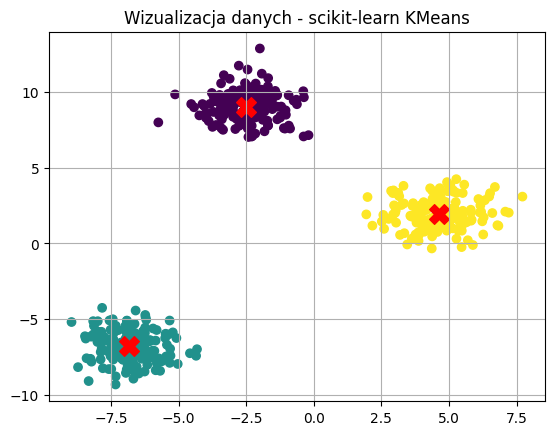

In [8]:
scikit_kmeans = KMeans(n_clusters=3)
scikit_kmeans.fit(X)
scikit_labels = scikit_kmeans.labels_
scikit_centroids = scikit_kmeans.cluster_centers_

plt.scatter(X[:, 0], X[:, 1], c=scikit_labels)
plt.scatter(scikit_centroids[:, 0], scikit_centroids[:, 1], c='r', marker='X', s=200, label='Centroidy')
plt.title('Wizualizacja danych - scikit-learn KMeans')
plt.grid(True)
plt.show()

In [9]:
def SSE(data, centroid_labels, centroids):
    result = 0
    for idx, label in enumerate(centroid_labels):
        result += euclidean_distance_squared(centroids[label], data[idx])
    return result


n = 100

implemented_kmeans_sse = np.mean([SSE(X, *kmeans(X, 3, init="random")) for _ in range(n)])
implemented_kmeans_sse_2 = np.mean([SSE(X, *kmeans(X, 3, init="k-means++")) for _ in range(n)])
scikit_kmeans_sse = 0
scikit_kmeans_sse_2 = 0
for _ in range(n):
    model = KMeans(n_clusters=3, init="random", n_init=1)
    model.fit(X)
    scikit_kmeans_sse += model.inertia_

    model = KMeans(n_clusters=3)
    model.fit(X)
    scikit_kmeans_sse_2 += model.inertia_
scikit_kmeans_sse /= n
scikit_kmeans_sse_2 /= n


result_df = pd.DataFrame({'Implementacja': [implemented_kmeans_sse, implemented_kmeans_sse_2],
                          'Scikit-learn': [scikit_kmeans_sse, scikit_kmeans_sse_2]},
                         index=['K-Means', 'K-Means++'])

display(result_df)

,Implementacja,Scikit-learn
K-Means,2205.816914,3207.379457
K-Means++,1122.338516,955.649343


Na podstawie wyników uśrednionych z 100 symulacji można zauważyć, że metoda K-Means++ osiąga istotnie niższe wartości funkcji celu (SSE) niż klasyczny algorytm K-Means, zarówno w implementacji własnej, jak i bibliotecznej. Jest to zgodne z teorią, ponieważ K-Means++ wykorzystuje bardziej przemyślaną inicjalizację centroidów, co znacząco zmniejsza ryzyko utkwienia w lokalnym minimum.

Dodatkowo, wyniki pokazują, że implementacje biblioteczne (np. z `scikit-learn`) wypadają lepiej od wersji własnych – co można przypisać lepszym optymalizacjom, dokładniejszym kryteriom zbieżności oraz bardziej dopracowanym procedurom inicjalizacji i aktualizacji centroidów.

## Zadanie 4
**Klastrowanie hierarchiczne**: Zastosuj algorytm klastrowania hierarchicznego (`AgglomerativeClustering` z `scikit-learn`) na syntetycznym zbiorze danych z zadania 1. Użyj różnych miar odległości (np. `linkage=’ward’`) i zwizualizuj wyniki za pomocą dendrogramu. Omów, jak wybór miary odległości wpływa na strukturę skupień.

In [10]:
def plot_dendrogram(ac_model: AgglomerativeClustering, **kwargs):
    """
    Tworzy dendrogram dla dopasowanego modelu AgglomerativeClustering.

    Funkcja konwertuje atrybuty modelu `AgglomerativeClustering` z biblioteki scikit-learn na macierz połączeń (`linkage matrix`), wymaganą przez `scipy.cluster.hierarchy.dendrogram`, a następnie rysuje dendrogram.

    :param ac_model: Dopasowany model klastrowania hierarchicznego. Musi być wytrenowanyz parametrem `compute_distances=True`, aby posiadał atrybut `distances_`.
    :param kwargs: Dodatkowe argumenty przekazywane bezpośrednio do funkcji `dendrogram()` z biblioteki `scipy.cluster.hierarchy`, przykładowo:
        - labels
        - color_threshold
        - leaf_rotation
        - leaf_font_size
        - truncate_mode
        - p
    """
    if not hasattr(ac_model, "distances_"):
        raise ValueError(
            "Model musi być dopasowany z compute_distances=True, "
            "aby można było wygenerować dendrogram."
        )

    counts = np.zeros(ac_model.children_.shape[0])
    n_samples = len(ac_model.labels_)

    for step, merge in enumerate(ac_model.children_):
        current_count = 0   # Liczba elementów w klastrze
        for child_idx in merge:
            if child_idx < n_samples:   # Klaster jednoelementowy (stworzony w pierwszym etapie, przy inicjalizacji)
                current_count += 1
            else:   # Klastry stworzone w wyniku połączenia innych klastrów - zawierają wiele elementów
                current_count += counts[child_idx - n_samples]
        counts[step] = current_count

    # Tworzenie macierzy powiązań
    linkage_matrix = np.column_stack(
        [ac_model.children_, ac_model.distances_, counts]
    ).astype(float)

    dendrogram(linkage_matrix, **kwargs)

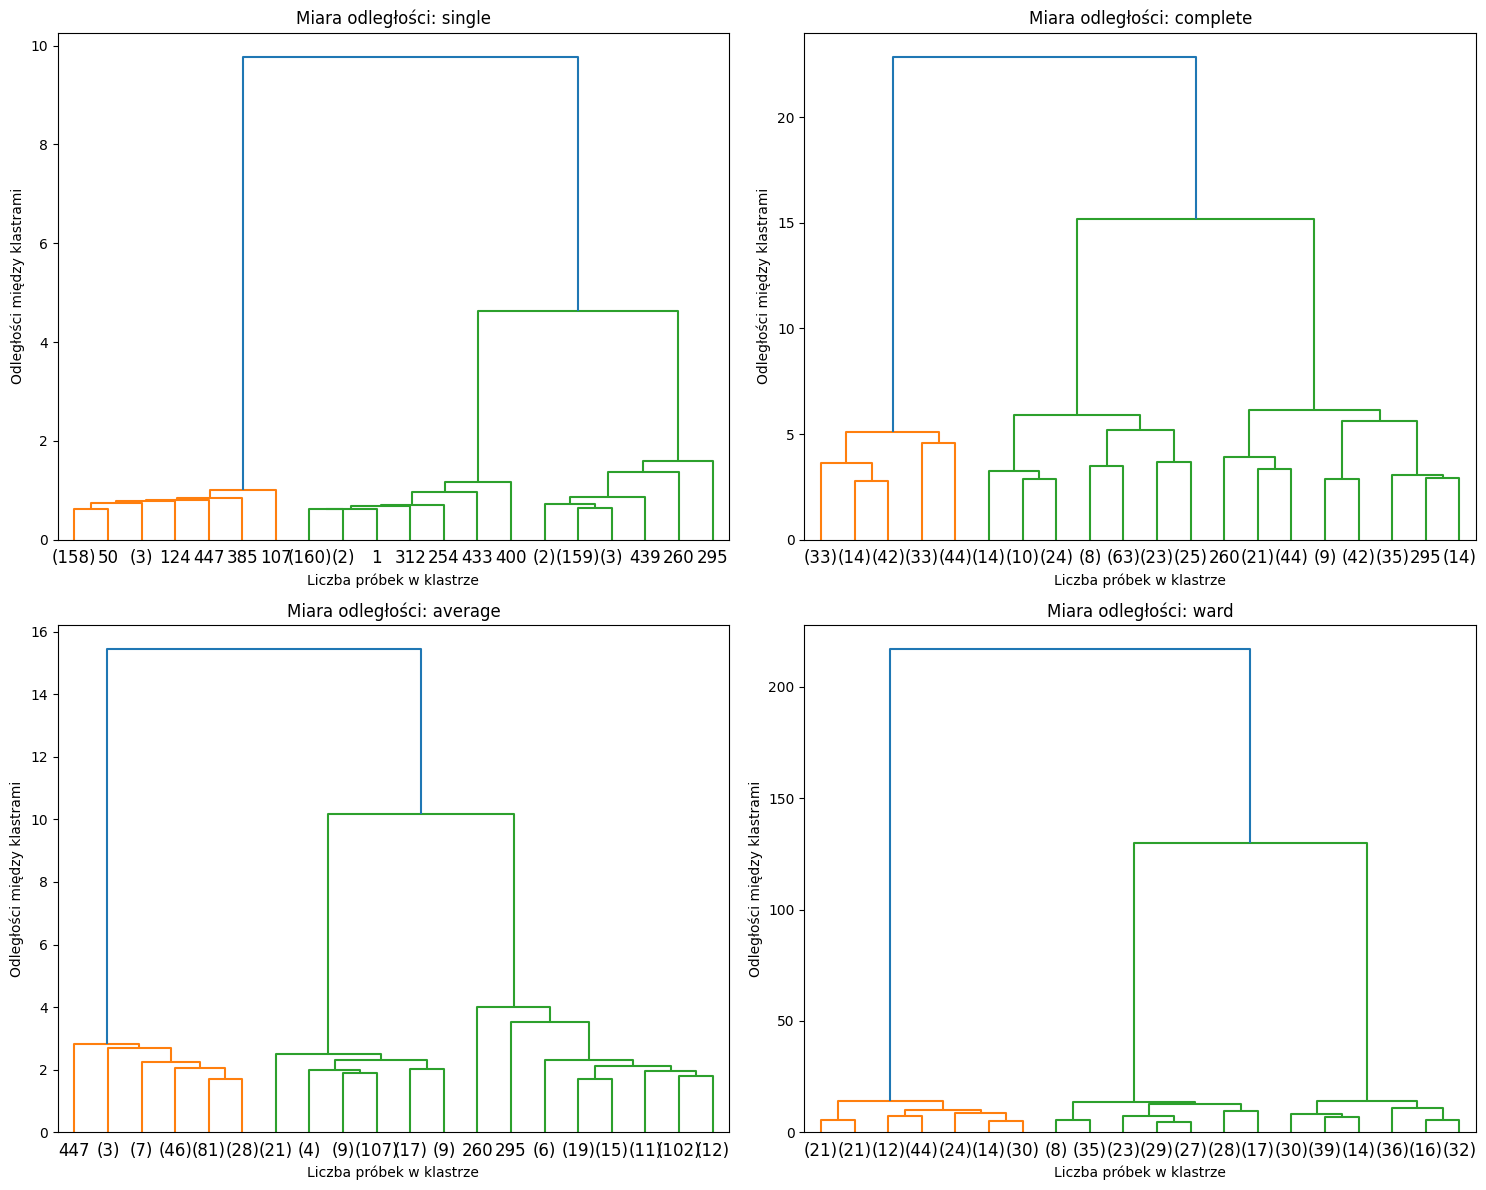

In [11]:
linkage_methods = ['single', 'complete', 'average', 'ward']
fig, axes = plt.subplots(2, 2, figsize=(15, 12))

for method in linkage_methods:
    model = AgglomerativeClustering(linkage=method, compute_distances=True)
    model = model.fit(X)
    ax = axes.flatten()[linkage_methods.index(method)]
    plt.sca(ax)
    plot_dendrogram(model, p=20, truncate_mode='lastp')
    ax.set_title(f"Miara odległości: {method}")
    ax.set_xlabel("Liczba próbek w klastrze")
    ax.set_ylabel("Odległości między klastrami")

plt.tight_layout()
plt.show()

Wpływ miary odległości na strukturę skupień:

- `single` – metoda łączy klastry na podstawie najmniejszej odległości między dowolnymi punktami z dwóch różnych klastrów. Jest wrażliwa na wartości odstające i często tworzy wydłużone, nieregularne skupienia.

- `complete` – metoda opiera się na największej odległości pomiędzy parami punktów z dwóch różnych klastrów. Dąży do tworzenia zwartych i wyraźnie oddzielonych grup, ponieważ unika łączenia klastrów, jeśli choć jeden punkt jest znacznie oddalony.

- `average` – metoda łączy klastry, dla których średnia odległość między wszystkimi parami punktów (po jednej z każdego klastra) jest najmniejsza. Stanowi kompromis między metodą `single` a `complete`, dając bardziej zrównoważone struktury skupień.

- `ward` – metoda łączy te klastry, których połączenie powoduje najmniejszy przyrost wewnątrzklastrowej wariancji (SSE – Sum of Squared Errors).

## Zadanie 5
**Ocena jakości klastrowania**: Zastosuj metodę łokcia (Elbow Method) oraz wskaźnik Silhouette, aby określić optymalną liczbę skupień dla zbioru danych `Iris`. Stwórz wykres dla obu metod i zinterpretuj wyniki.
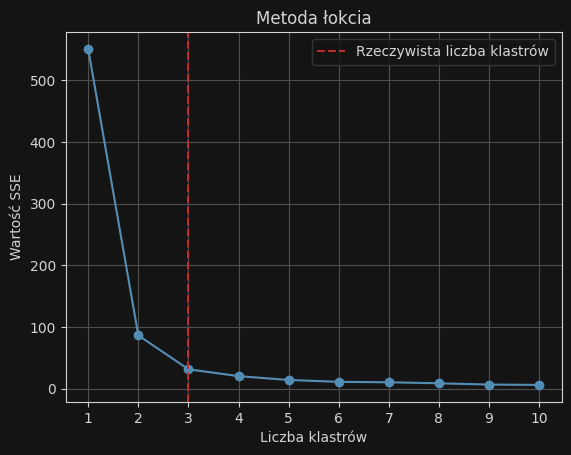

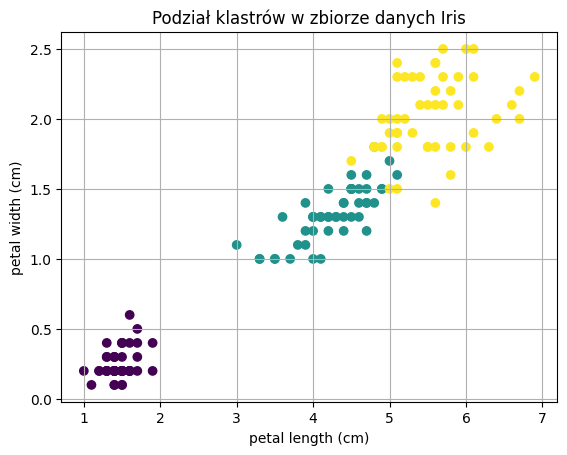

In [12]:
from sklearn.datasets import load_iris
from sklearn.metrics import silhouette_score


iris_df = load_iris(as_frame=True).frame

X_iris = np.array(iris_df[['petal length (cm)', 'petal width (cm)']])
plt.scatter(X_iris[:, 0], X_iris[:, 1], c=iris_df['target'])
plt.title('Podział klastrów w zbiorze danych Iris')
plt.grid(True)
plt.xlabel('petal length (cm)')
plt.ylabel('petal width (cm)')
plt.show()

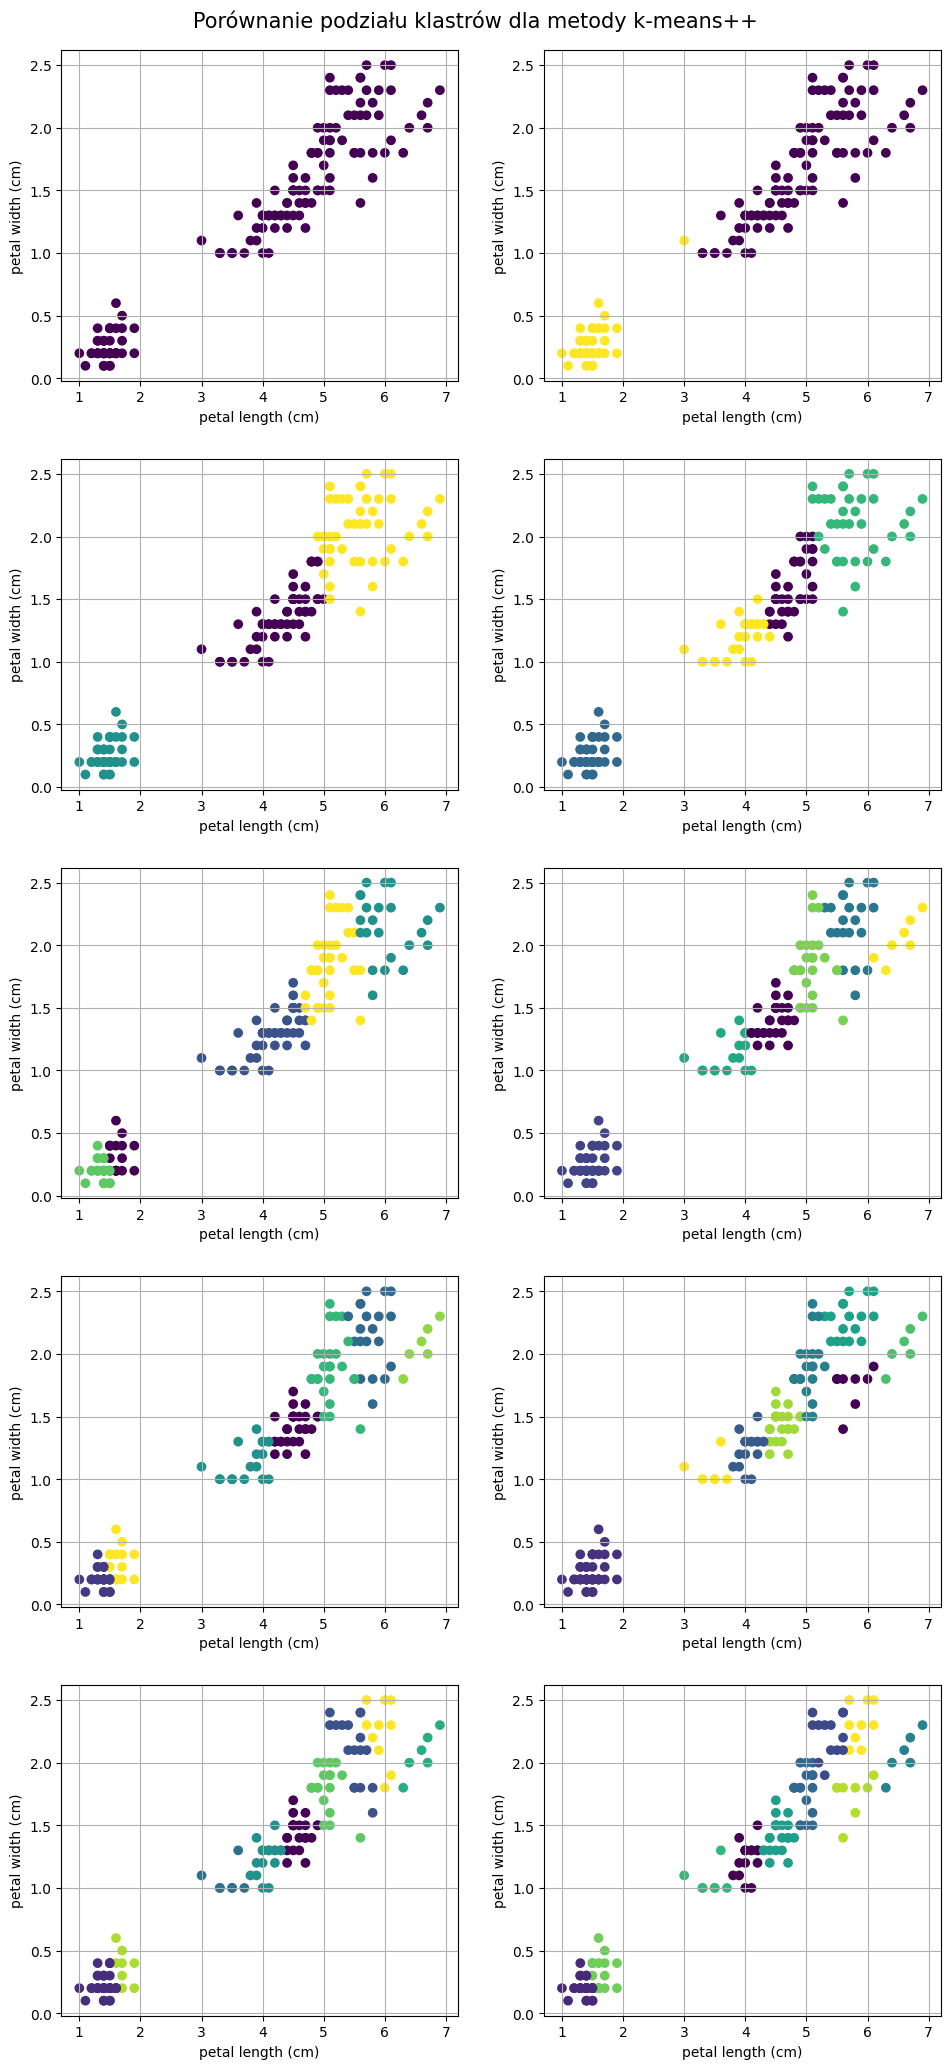

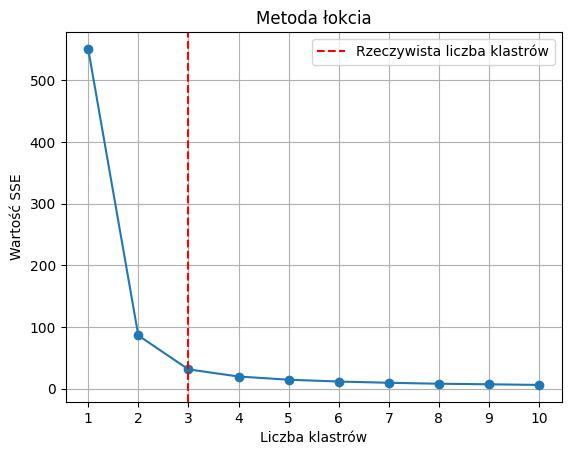

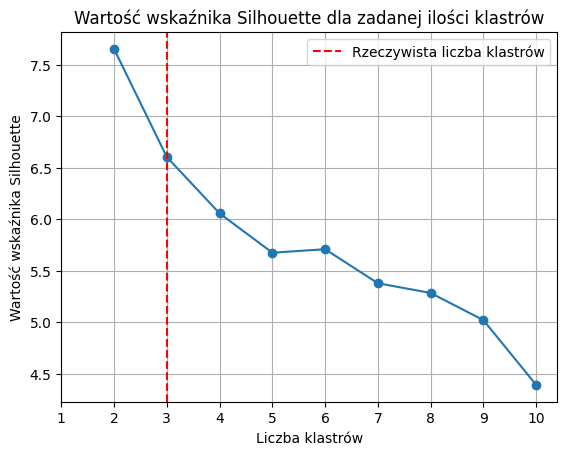

In [13]:
iris_sse = []
iris_sil = []

max_k = 10
plt.figure(figsize=(10, 25))
for i in range(1, max_k + 1):
    avg_sse = 0
    avg_sil = 0
    for _ in range(10):
        kmeans = KMeans(n_clusters=i)
        kmeans.fit(X_iris)
        x_labels = kmeans.labels_
        avg_sse += kmeans.inertia_
        avg_sil = avg_sil + silhouette_score(X_iris, kmeans.labels_) if i > 1 else None
    iris_sse.append(avg_sse / 10)
    iris_sil.append(avg_sil) if i > 1 else iris_sil.append(None)
    ax = plt.subplot(max_k // 2 + 1, 2, i)
    ax.scatter(X_iris[:, 0], X_iris[:, 1], c=x_labels)
    ax.set_xlabel('petal length (cm)')
    ax.set_ylabel('petal width (cm)')
    ax.grid(True)

plt.suptitle("Porównanie podziału klastrów dla metody k-means++", fontsize=15)
plt.tight_layout(pad=2.5)
plt.show()

plt.plot(np.arange(1, max_k + 1), iris_sse, marker='o')
plt.axvline(3, color='red', linestyle='--', label="Rzeczywista liczba klastrów")
plt.xticks(np.arange(1, max_k + 1))
plt.grid(True)
plt.title("Metoda łokcia")
plt.xlabel("Liczba klastrów")
plt.ylabel("Wartość SSE")
plt.legend()
plt.show()

plt.plot(np.arange(1, max_k + 1), iris_sil, marker='o')
plt.axvline(3, color='red', linestyle='--', label="Rzeczywista liczba klastrów")
plt.xticks(np.arange(1, max_k + 1))
plt.grid(True)
plt.title("Wartość wskaźnika Silhouette dla zadanej ilości klastrów")
plt.xlabel("Liczba klastrów")
plt.ylabel("Wartość wskaźnika Silhouette")
plt.legend()
plt.show()

Zarówno metoda łokcia, jak i metoda wskaźnika Silhouette prawidłowo wskazują optymalną liczbę klastrów na poziomie k = 3. Choć wskaźnik Silhouette osiąga wyższą wartość dla k = 2, jego wysoka wartość dla k = 3 potwierdza poprawność działania obu metod i zgodność wyników z rzeczywistym podziałem gatunkowym w zbiorze Iris.

## Zadanie 6
**Zastosowanie algorytmu DBSCAN**: Użyj klasy `DBSCAN` z biblioteki `scikit-learn` do pogrupowania danych z zadania 1. Przetestuj różne wartości parametrów `eps` i `min_samples` i zaobserwuj, jak wpływają one na wyniki klastrowania. Zidentyfikuj ”szum” (punkty odstające).

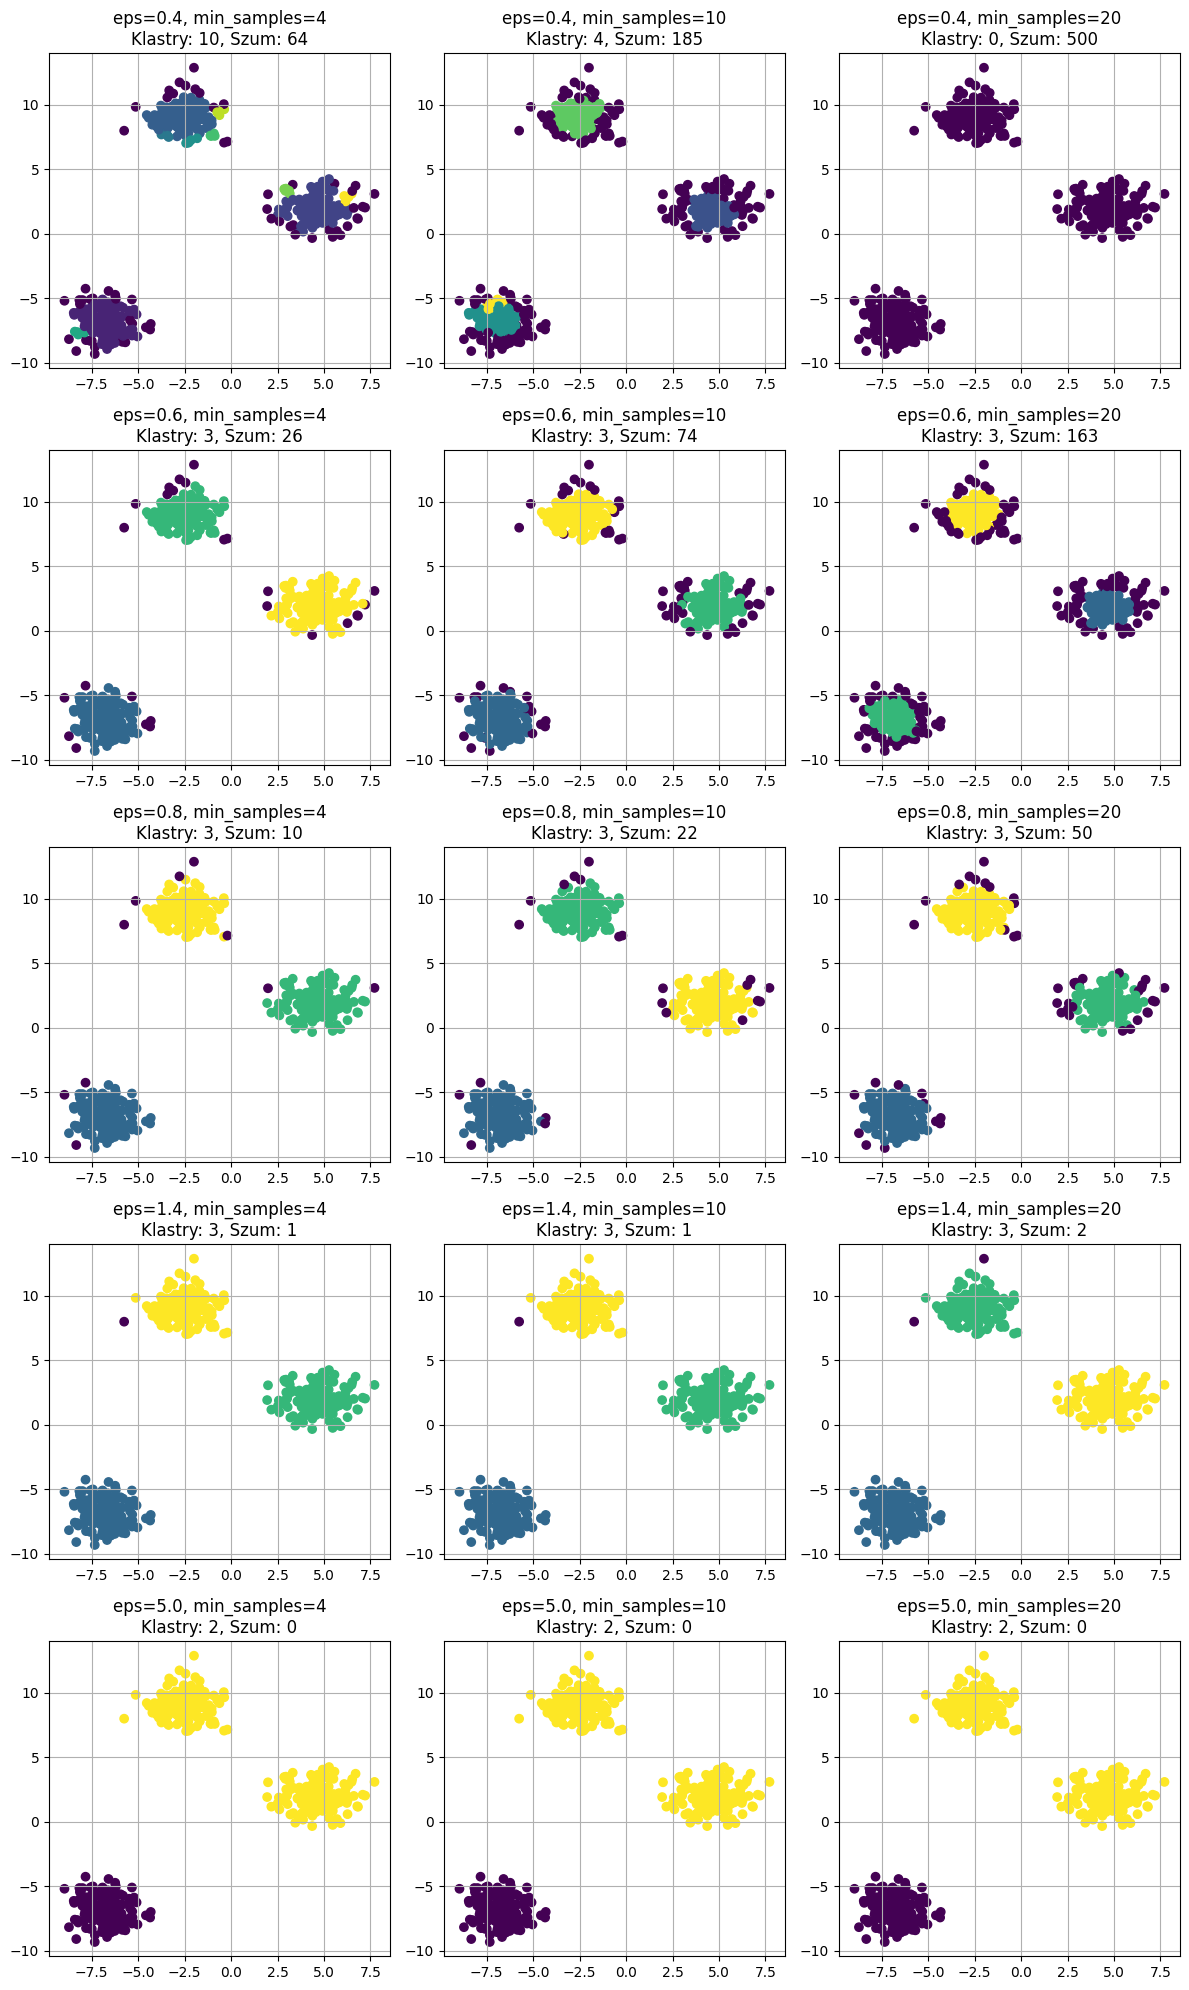

In [14]:
from sklearn.cluster import DBSCAN


eps_values = [0.4, 0.6, 0.8, 1.4, 5.0]
min_samples_values = [4, 10, 20]

fig, axes = plt.subplots(len(eps_values), len(min_samples_values),
                        figsize=(12, 20))

for i, eps in enumerate(eps_values):
    for j, min_samples in enumerate(min_samples_values):
        dbscan = DBSCAN(eps=eps, min_samples=min_samples).fit(X)
        labels = dbscan.labels_

        n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
        n_noise = list(labels).count(-1)

        ax = axes[i, j]
        scatter = ax.scatter(X[:, 0], X[:, 1],
                           c=labels, cmap='viridis')
        ax.set_title(f'eps={eps}, min_samples={min_samples}\n'
                     f'Klastry: {n_clusters}, '
                    f'Szum: {n_noise}')
        ax.grid()

plt.tight_layout()
plt.show()

## Zadanie 7

**Analiza danych rzeczywistych**: Wczytaj zbiór danych dotyczący klientów (np. `Mall Customer Segmentation Data` z Kaggle). Przeprowadź analizę skupień na podstawie wybranych cech (np. wiek i roczny dochód). Zastosuj algorytm k-means i zwizualizuj otrzymane segmenty klientów. Zinterpretuj wyniki.

In [15]:
import kagglehub


path = kagglehub.dataset_download("vjchoudhary7/customer-segmentation-tutorial-in-python")
print("Path to dataset files:", path)

/Users/zuzannasosnowska/PycharmProjects/UniversityProjects/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Path to dataset files: /Users/zuzannasosnowska/.cache/kagglehub/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python/versions/1


In [16]:
path_to_csv = path + "/Mall_Customers.csv"
dataframe = pd.read_csv(path_to_csv)

display(dataframe.head())

print(dataframe.info())
print(dataframe.describe())

print("Brakujące wartości : \n",dataframe.isnull().sum())

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB
None
       CustomerID         Age  Annual Income (k$)  Spending Score (1-100)
count  200.000000  200.000000          200.000000              200.000000
mean   100.500000   38.850000           60.560000               50.200000
std     57.879185   13.969007           26.264721               25.823522
min      1.000000   18.000000           15.000000                1.000000
25%     50.750000   28.750000           41.500000               34.750000
50%    100.500000   36.000000    

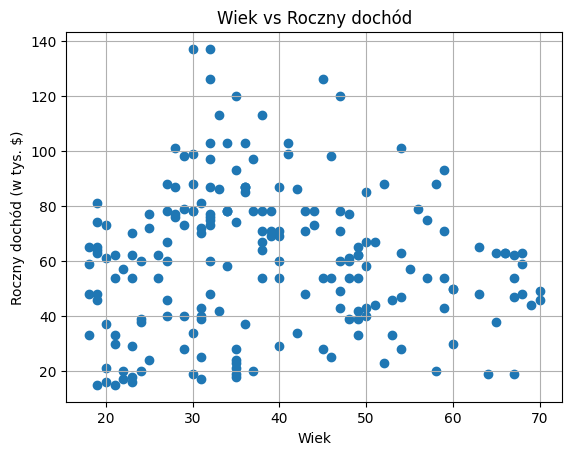

In [17]:
X = np.array(dataframe[['Age', 'Annual Income (k$)']])
plt.scatter(X[:, 0], X[:, 1])
plt.title('Wiek vs Roczny dochód')
plt.xlabel('Wiek')
plt.ylabel('Roczny dochód (w tys. $)')
plt.grid(True)
plt.show()

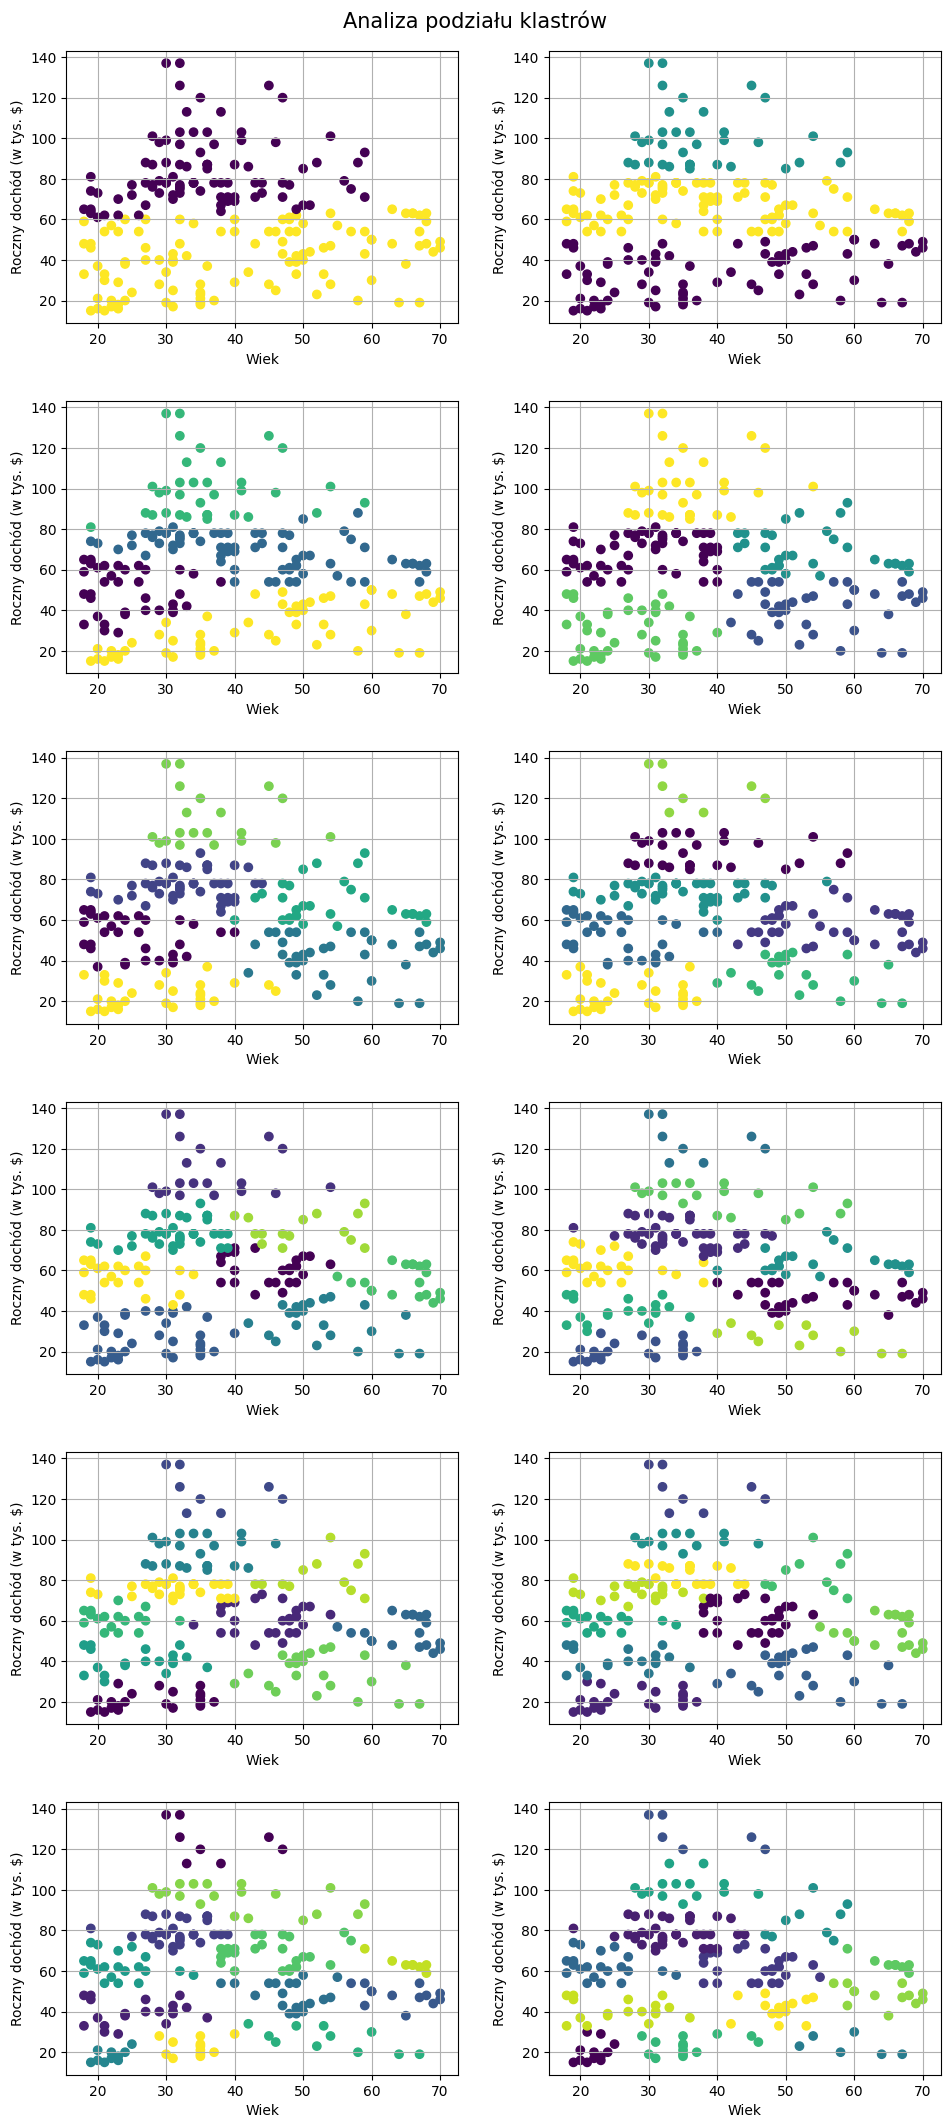

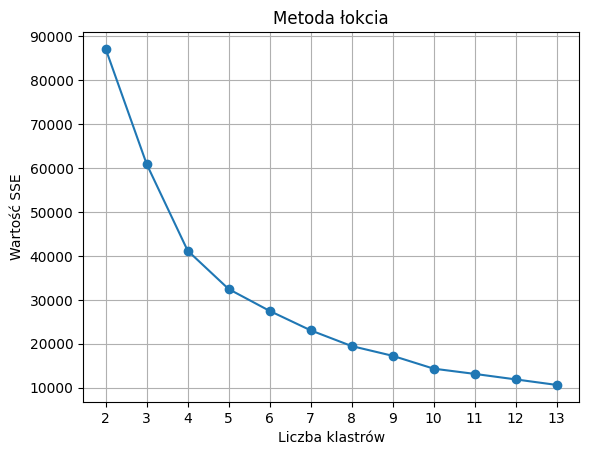

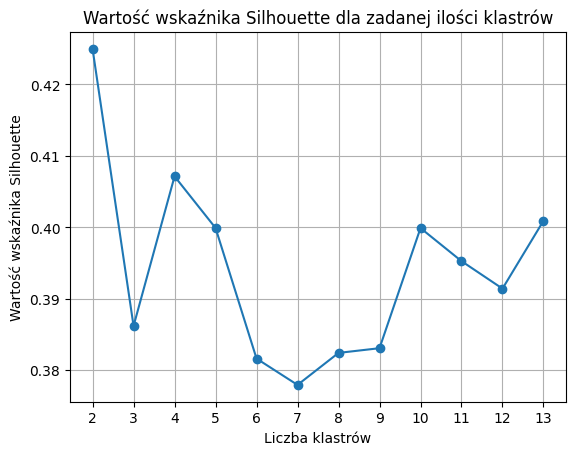

In [18]:
sse = []
sil = []

max_k = 13
plt.figure(figsize=(10, 25))
for i in range(2, max_k + 1):
    avg_sse = 0
    avg_sil = 0
    for _ in range(10):
        kmeans = KMeans(n_clusters=i)
        kmeans.fit(X)
        x_labels = kmeans.labels_
        avg_sse += kmeans.inertia_
        avg_sil += silhouette_score(X, labels=x_labels)
    sse.append(avg_sse / 10)
    sil.append(avg_sil / 10)
    ax = plt.subplot(max_k // 2 + 1 , 2, i - 1)
    ax.scatter(X[:, 0], X[:, 1], c=x_labels)
    ax.set_xlabel('Wiek')
    ax.set_ylabel('Roczny dochód (w tys. $)')
    ax.grid(True)

plt.suptitle("Analiza podziału klastrów", fontsize=15)
plt.tight_layout(pad=2.5)
plt.show()

plt.plot(np.arange(2, max_k + 1), sse, marker='o')
plt.xticks(np.arange(2, max_k + 1))
plt.grid(True)
plt.title("Metoda łokcia")
plt.xlabel("Liczba klastrów")
plt.ylabel("Wartość SSE")
plt.show()

plt.plot(np.arange(2, max_k + 1), sil, marker='o')
plt.xticks(np.arange(2, max_k + 1))
plt.grid(True)
plt.title("Wartość wskaźnika Silhouette dla zadanej ilości klastrów")
plt.xlabel("Liczba klastrów")
plt.ylabel("Wartość wskaźnika Silhouette")
plt.show()

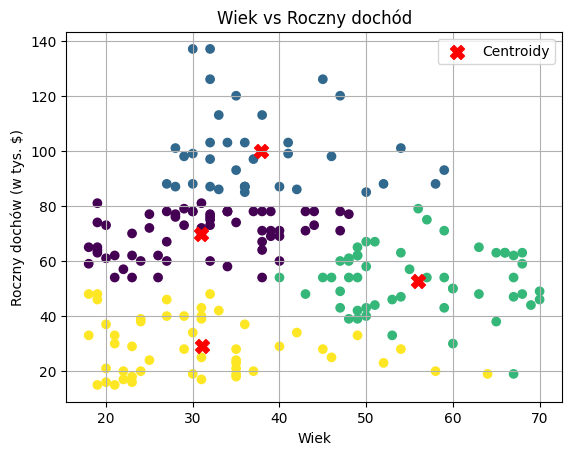

In [19]:
scikit_kmeans = KMeans(n_clusters=4).fit(X)
scikit_labels = scikit_kmeans.labels_
scikit_centroids = scikit_kmeans.cluster_centers_

plt.scatter(dataframe['Age'], dataframe['Annual Income (k$)'], c=scikit_labels)
plt.scatter(scikit_centroids[:,0], scikit_centroids[:,1], c='red', marker='X', s=100, label='Centroidy')
plt.title('Wiek vs Roczny dochód')
plt.xlabel('Wiek')
plt.ylabel('Roczny dochów (w tys. $)')
plt.legend()
plt.grid(True)
plt.grid(True)
plt.show()

Na podstawie analizy skupień metodą K-średnich (K-Means), przeprowadzonej dla cech wiek oraz roczny dochód, wyodrębniono cztery wyraźne segmenty klientów. Wśród nich można wyróżnić: młodsze osoby (20–40 lat) o niższych dochodach, starszych klientów (45+) o średnich dochodach, grupę klientów w średnim wieku o umiarkowanych dochodach oraz osoby w wieku około 30–55 lat osiągające wyższe dochody. Wyniki te wskazują, że zarówno wiek, jak i poziom dochodu mają istotny wpływ na strukturę segmentacji klientów i mogą stanowić podstawę do dalszej analizy zachowań zakupowych.